# Radial synthesis — multi-scenario

Radial wheel of the planetary boundaries (LP): 1 sector per LP, 1 radial bar
per scenario (height = value / Safe Limit, so the Safe Limit is a circle of
constant radius = 1L), annotated outer ring (overshoot level for the reference
scenario, % variation for the others) and Upper Safe Bound arc specific to
each sector (the Upper Safe Bound / Safe Limit ratio varies with the LP).
No color gradient between scenarios: only the angular position (and the text
of the outer ring) distinguishes them within a sector.

Reuses the same data as `footprint_decomposition.ipynb`
(`create_synthesis_figure_by_lp`), shown in a radial form rather than as a
grid of subplots.

Generates 2 figures in `figures/<SCENARIO_GROUP>/`:
- `radial_synthesis_cba_all_scenarios.png`: domestic (solid) + imported
  (hatched) bars stacked by consumption category, like
  `create_stacked_bar_chart` (can be switched on/off with `show_categories` /
  `show_import_split`).
- `radial_synthesis_pba_all_scenarios.png`: solid bar, colored by LP --
  the PBA is a single scalar in the source data, with no breakdown by
  category or domestic/imported possible.

Computation and plotting logic shared with the other notebooks through the
[`planefr_lib`](./planefr_lib/) package.

In [1]:
import sys
from pathlib import Path

notebooks_dir = Path.cwd()
while not (notebooks_dir / "planefr_lib").exists() and notebooks_dir != notebooks_dir.parent:
    notebooks_dir = notebooks_dir.parent
if str(notebooks_dir) not in sys.path:
    sys.path.insert(0, str(notebooks_dir))

import matplotlib.pyplot as plt

from planefr_lib import config, io, processing
from planefr_lib.plot_radial_synthesis import create_radial_synthesis_figure

## 1. Loading the data and processing the scenarios

In [2]:
# Scenario group to display: "no_SSP", "SSP1_2050", "SSP2_2050"... (see config.get_scenario_groups())
# A "{scenario}_agri" group uses the "Agri" sheets of characterization_factors.xlsx and thresholds.xlsx
SCENARIO_GROUP = "SSP_all"

cf_df = io.load_characterization_factors(SCENARIO_GROUP)
bridge_matrices_df = io.load_bridge_matrices()
thresholds_df = io.load_thresholds(SCENARIO_GROUP)
dls_df = io.load_dls()

# The figures are saved in a sub-folder specific to each scenario group
group_figures_dir = config.FIGURES_DIR / SCENARIO_GROUP
group_figures_dir.mkdir(parents=True, exist_ok=True)
scenario_folders = config.get_scenario_folders(exclude_2019=True, scenario_group=SCENARIO_GROUP)
scenario_names = [f.name for f in scenario_folders]
print(f"Scenarios found ({len(scenario_folders)}): {scenario_names}")

all_scenarios_data = []
for scenario_folder in scenario_folders:
    print(f"Processing: {scenario_folder.name}")
    data_by_subprocess, _ = processing.process_scenario(
        scenario_folder, cf_df, bridge_matrices_df, thresholds_df
    )
    all_scenarios_data.append(data_by_subprocess)

assert len(all_scenarios_data) == len(scenario_folders), "Some scenarios produced no data"
print(f"\n{len(all_scenarios_data)}/{len(scenario_folders)} scenarios processed successfully.")

c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\config.py:140: UserWarning: Group 'SSP_all' does not contain Base_year_2015: the reference scenario (REFERENCE_SCENARIO_IDX) will be the first one in alphabetical order.
  warnings.warn(


Scenarios found (5): ['2015', 'S1', 'S1+', 'S4', 'TREND']
Processing: 2015
Processing: S1
Processing: S1+
Processing: S4
Processing: TREND

5/5 scenarios processed successfully.


## 2. Radial wheel — consumption-based accounting (CBA)

Stacked bars: domestic (solid) + imported (hatched), by consumption
category. Set `show_categories=False` and/or `show_import_split=False` to
simplify the styling (the bar then goes back to a solid color, that of the
LP, like the PBA figure below).

`radial_power=1/3` dilates the radial scale more strongly than a square root:
the LPs below their Safe Limit (e.g. Blue water consumption) remain visible,
without the LPs in large overshoot (e.g. GHG emissions) squashing the rest of
the figure. Raise it towards 1.0 for a strictly linear scale.

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\SSP_all\radial_synthesis_cba_all_scenarios.png


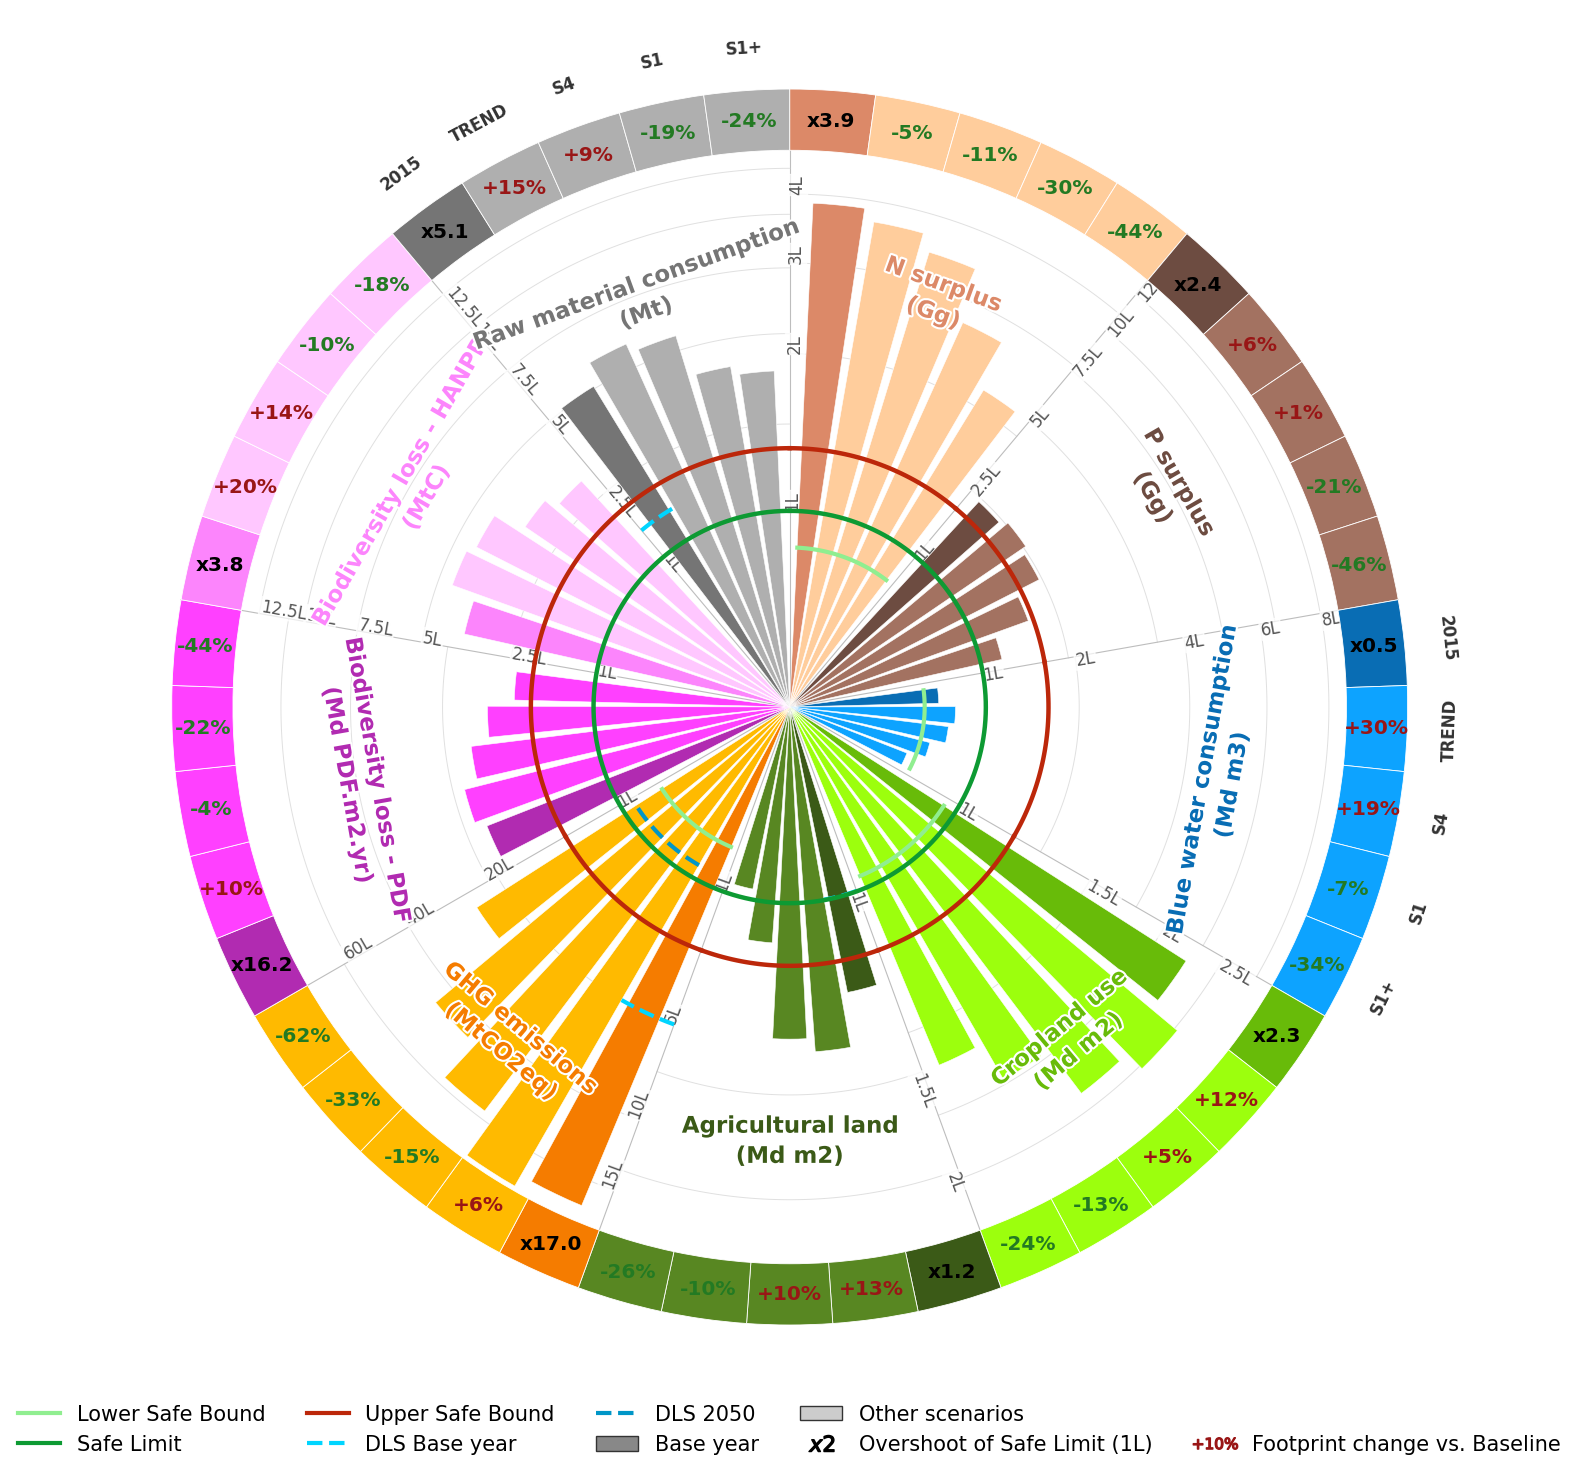

In [9]:
fig_cba, _ = create_radial_synthesis_figure(
    all_scenarios_data, thresholds_df, scenario_names,
    show_cba=True, show_pba=False,
    dls_df=dls_df, show_dls=True, Bdf=None,
    radial_power=0.4, display_bounds=True, scale_diff=False,
    show_categories=False, show_import_split=False, scale_UB=True,
    sharing_principle="EPC",
    scenario_group=SCENARIO_GROUP,
)

output_path = group_figures_dir / "radial_synthesis_cba_all_scenarios.png"
fig_cba.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

## 3. Radial wheel — production-based accounting (PBA)

The PBA is a single scalar in the source data (no breakdown by category or
domestic/imported): the bar is therefore always solid, colored by LP.

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\SSP_all\radial_synthesis_pba_all_scenarios.png


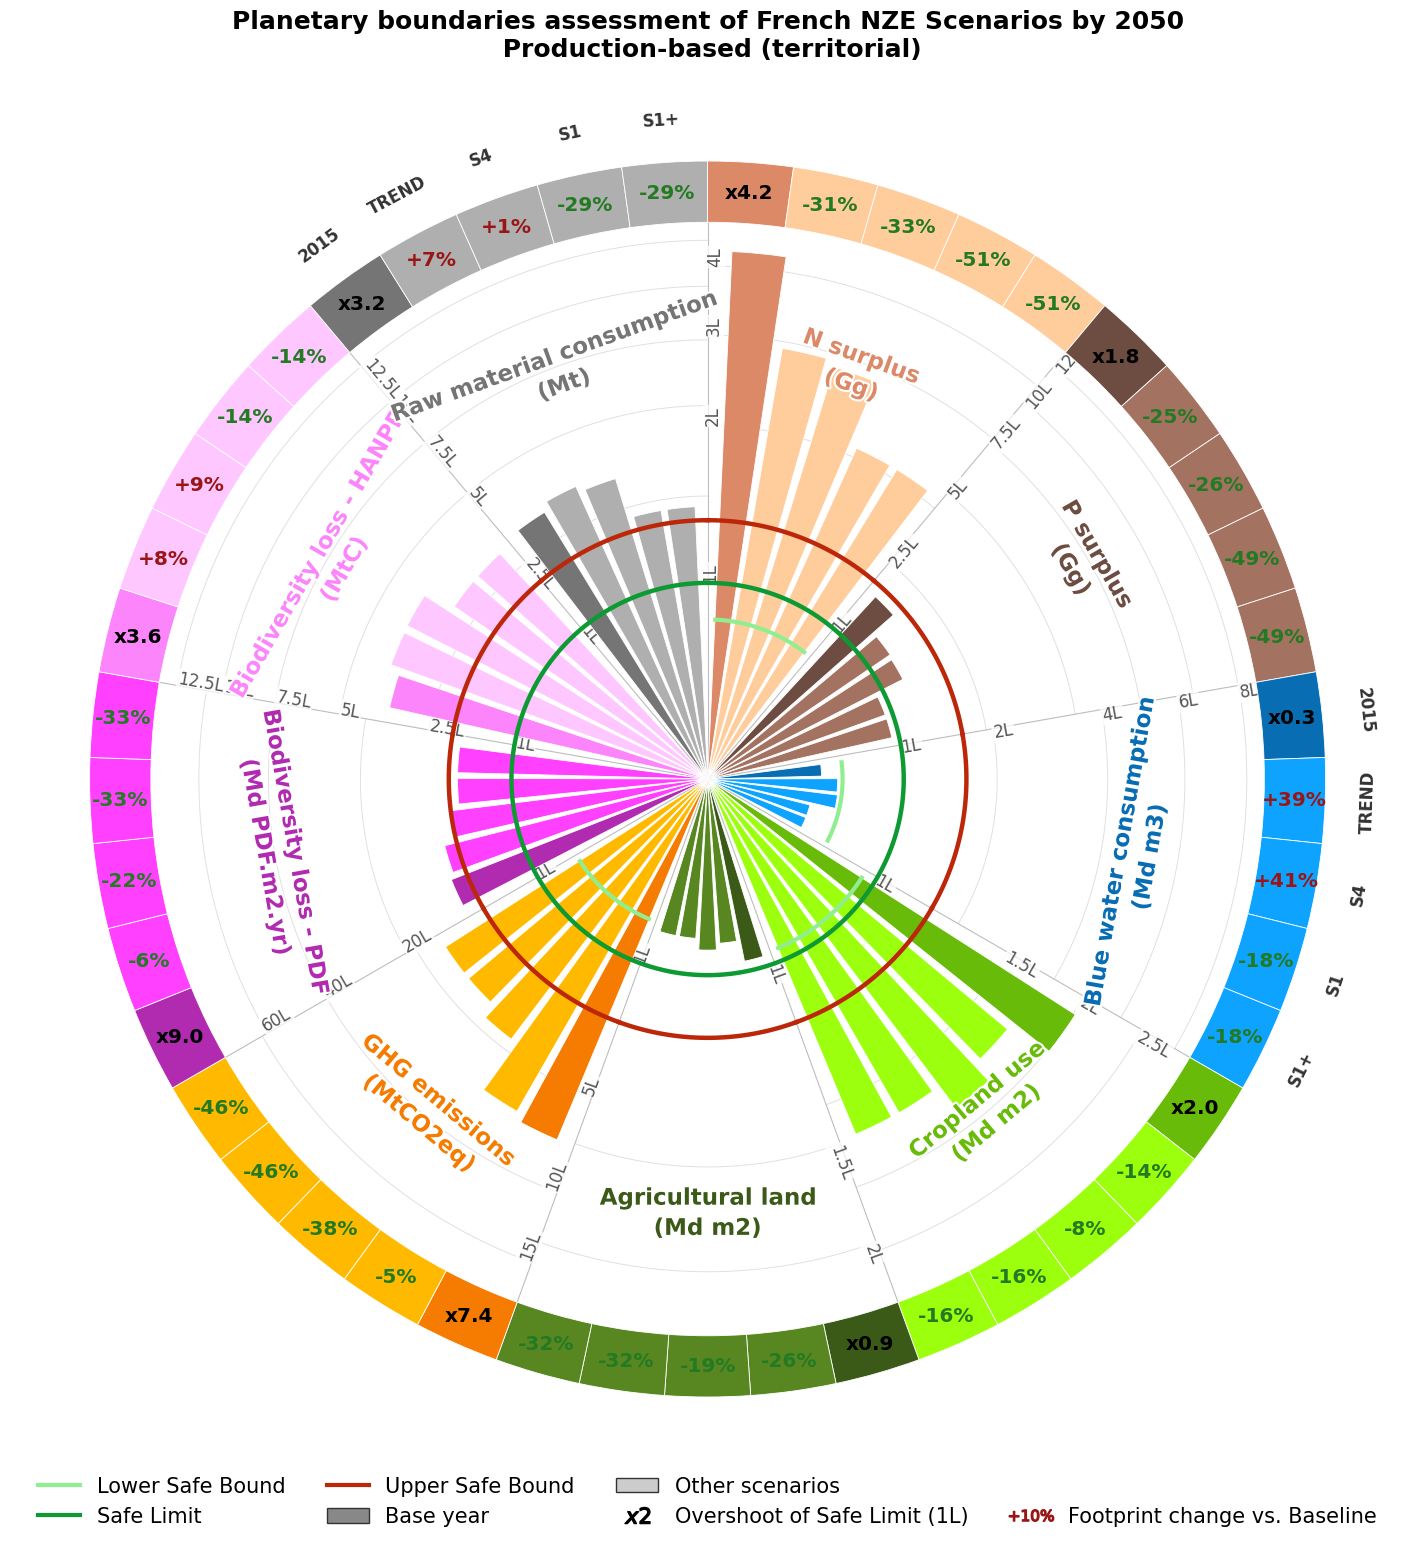

In [4]:
fig_pba, _ = create_radial_synthesis_figure(
    all_scenarios_data, thresholds_df, scenario_names,
    show_cba=False, show_pba=True,
    dls_df=dls_df, show_dls=False, scale_UB=True,
    radial_power=0.4,
    title="Planetary boundaries assessment of French NZE Scenarios by 2050\n Production-based (territorial)",
    sharing_principle="EPC",
    scenario_group=SCENARIO_GROUP,
)

output_path = group_figures_dir / "radial_synthesis_pba_all_scenarios.png"
fig_pba.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()